ALPHA  (driver detection)  -- random-node threshold = 7
  PWY2     (MARKER)  alpha = 117  <- above null
  PWY6     (MARKER)  alpha = 114  <- above null
  PWY5     (MARKER)  alpha =  99  <- above null
  PWY1     (MARKER)  alpha =  97  <- above null
  PWY4     (MARKER)  alpha =  92  <- above null
  PWY3     (MARKER)  alpha =  83  <- above null
  NULL20   (null  )  alpha =  65  <- above null
  NULL27   (null  )  alpha =  43  <- above null
  NULL28   (null  )  alpha =  41  <- above null
  NULL11   (null  )  alpha =  38  <- above null

BETA   (interaction discovery) -- random-node threshold = 1
  GROUND TRUTH: there are ZERO interactions in the generator.
  PWY2    -PWY6      beta = 107  (Conj)   [SPURIOUS: both co-markers]
  PWY2    -PWY4      beta =  82  (Disj)   [SPURIOUS: both co-markers]
  PWY2    -PWY5      beta =  74  (Disj)   [SPURIOUS: both co-markers]
  PWY1    -PWY2      beta =  70  (Disj)   [SPURIOUS: both co-markers]
  PWY4    -PWY6      beta =  70  (Conj)   [SPURIOUS: both co-

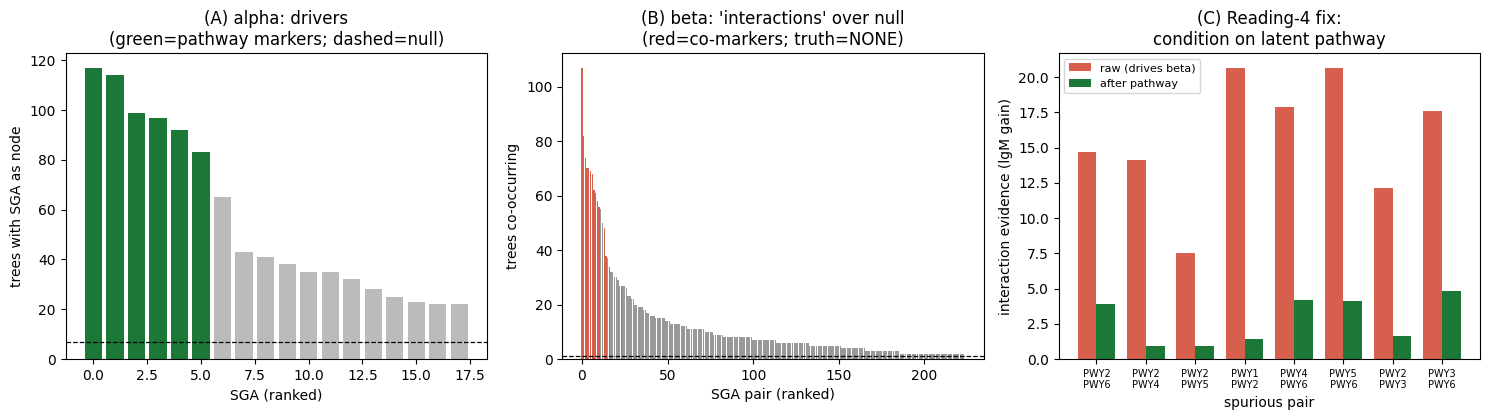

In [3]:
"""
Faithful mini IBI-DT  +  where it breaks  +  the pathway-level (Reading 4) fix
=============================================================================
The marginal-likelihood (lgM) is copied EXACTLY from the authors' IBI_core.py
(DriverSearch): for each parent config V in {0,1}, a uniform Dirichlet(1,1)
prior over the trait's two states, scored with loggamma. So per edge V -> T:

    lgM(V->T) = sum_{j in {0,1}} [ lgamma(2) - lgamma(2 + N_j)
                                   + lgamma(1 + N_j0) + lgamma(1 + N_j1) ]

(lgamma(1)=0, lgamma(2)=0). The tree applies this recursively: at each node it
picks the SGA with the highest lgM in the current subgroup, splits on its 0/1
status, and recurses. We read off only alpha (node appearances) and beta
(same-path co-occurrence), exactly as in the paper -- leaf labels are ignored.

Structure prior P(Model)=q^|path| (Eq.2): a split is kept only if its lgM gain
exceeds the depth penalty -log q (Eq.3). Bootstrap ensemble of N trees (Eq, N=200
in the paper). Random-node experiment gives the null threshold for alpha/beta.

WHAT THIS SHOWS
  - alpha correctly elevates the real drivers  (IBI-DT works as a driver finder)
  - beta MANUFACTURES interactions between genes that are merely co-markers of a
    shared latent pathway -- there are ZERO true interactions in the generator,
    yet many marker-marker pairs clear the random-node beta threshold.
  - FIX (Reading 4): estimate a latent pathway activity Z_hat; the pathway-level
    posterior P(pathway relevant) is ~1, and once you condition on Z_hat the
    "interaction" evidence for the spurious pairs collapses to ~0.
"""

import numpy as np
from scipy.special import gammaln
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

# ----------------------------------------------------------------------------
# 1.  IBI marginal likelihood  (exact replica of authors' DriverSearch)
# ----------------------------------------------------------------------------
def lgm_edge(T, Vmat):
    """log marginal likelihood of edge V->T, for every column of Vmat at once.
    T : (n,) 0/1 trait.  Vmat : (n,p) 0/1.  returns (p,)."""
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1 = T; t0 = 1 - T
    V1D1 = t1 @ Vmat;        V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat);  V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for (a, b) in [(V0D0, V0D1), (V1D0, V1D1)]:          # j=0 then j=1
        lg += gammaln(2.0) - gammaln(2.0 + a + b)
        lg += gammaln(1.0 + a) - gammaln(1.0)
        lg += gammaln(1.0 + b) - gammaln(1.0)
    return lg

def lgm_noparent(T):
    """log marginal likelihood of T with no parent (single Dirichlet(1,1))."""
    N = len(T); N1 = int(T.sum()); N0 = N - N1
    return (gammaln(2.0) - gammaln(2.0 + N)
            + gammaln(1.0 + N0) - gammaln(1.0)
            + gammaln(1.0 + N1) - gammaln(1.0))

# ----------------------------------------------------------------------------
# 2.  one IBI-DT tree  (greedy, depth-penalised); records nodes + paths
# ----------------------------------------------------------------------------
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    """idx: row indices in current subgroup. Appends completed paths (lists of
    (var, branch_value_taken_from_var)) to `paths`."""
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    Vsub = V[np.ix_(idx, cand)]
    varying = (Vsub.min(0) != Vsub.max(0))
    usable = [c for c, ok in zip(cand, varying) if ok and c not in used]
    if not usable:
        paths.append(list(path)); return
    scores = lgm_edge(Tn, V[np.ix_(idx, usable)])
    gains = scores - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:                       # split doesn't beat the prior
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):                          # split on s's 0/1 status
        child = idx[V[idx, s] == branch]
        if len(child) == 0:
            continue
        grow(T, V, child, cand, depth + 1, max_depth, neglogq, min_n,
             used | {s}, path + [(s, branch)], paths)

def fit_tree(T, V, cand, max_depth=4, q=0.1, min_n=20):
    paths = []
    grow(T, V, np.arange(len(T)), cand, 0, max_depth, -np.log(q), min_n,
         set(), [], paths)
    nodes = {v for p in paths for (v, _) in p}
    return nodes, paths

# ----------------------------------------------------------------------------
# 3.  ensemble -> alpha (node freq) and beta (same-path co-occurrence freq)
# ----------------------------------------------------------------------------
def ensemble(T, V, cand, N=120, **kw):
    p = V.shape[1]
    alpha = np.zeros(p)
    beta = {}                                       # (a,b)->count ; a<b
    btype = {}                                       # (a,b)->[conj,disj]
    n = len(T)
    for _ in range(N):
        # stratified bootstrap (preserve trait proportions), as in the paper
        i1 = rng.choice(np.where(T == 1)[0], (T == 1).sum(), replace=True)
        i0 = rng.choice(np.where(T == 0)[0], (T == 0).sum(), replace=True)
        bs = np.concatenate([i0, i1])
        nodes, paths = fit_tree(T[bs], V[bs], cand, **kw)
        for s in nodes:
            alpha[s] += 1
        seen = set()
        for path in paths:
            for a in range(len(path)):
                for b in range(a + 1, len(path)):
                    va, ba = path[a]; vb, _ = path[b]
                    key = (min(va, vb), max(va, vb))
                    if key not in seen:
                        beta[key] = beta.get(key, 0) + 1
                        seen.add(key)
                    bt = btype.setdefault(key, [0, 0])
                    bt[0 if ba == 1 else 1] += 1     # parent mutated -> conj
    return alpha, beta, btype

def random_node_null(T, V, cand, N=120, **kw):
    """Authors' control: keep tree shapes, replace each node by a random SGA."""
    p = V.shape[1]
    a_max = 0; b_max = 0
    for _ in range(N):
        i1 = rng.choice(np.where(T == 1)[0], (T == 1).sum(), replace=True)
        i0 = rng.choice(np.where(T == 0)[0], (T == 0).sum(), replace=True)
        bs = np.concatenate([i0, i1])
        _, paths = fit_tree(T[bs], V[bs], cand, **kw)
        # relabel nodes randomly
        a_cnt = {}; b_seen = set(); b_cnt = {}
        for path in paths:
            relabel = {v: int(rng.integers(p)) for (v, _) in path}
            rl = [relabel[v] for (v, _) in path]
            for v in set(rl):
                a_cnt[v] = a_cnt.get(v, 0) + 1
            for a in range(len(rl)):
                for b in range(a + 1, len(rl)):
                    key = (min(rl[a], rl[b]), max(rl[a], rl[b]))
                    if key not in b_seen:
                        b_cnt[key] = b_cnt.get(key, 0) + 1; b_seen.add(key)
        if a_cnt: a_max = max(a_max, max(a_cnt.values()))
        if b_cnt: b_max = max(b_max, max(b_cnt.values()))
    return a_max, b_max

# ----------------------------------------------------------------------------
# 4.  GENERATOR: phenotype driven by a LATENT pathway; genes are co-markers
#     with NO direct effect and NO pairwise interactions.
# ----------------------------------------------------------------------------
n = 700
m_markers = 6                     # noisy readouts of the latent pathway
n_null = 30                       # unrelated SGAs
p = m_markers + n_null
names = [f"PWY{j+1}" for j in range(m_markers)] + [f"NULL{j+1}" for j in range(n_null)]

Z = (rng.random(n) < 0.40).astype(int)                         # latent pathway state
V = np.zeros((n, p), dtype=int)
theta1, theta0 = 0.75, 0.15
for j in range(m_markers):                                     # markers track Z
    V[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(int)
for j in range(m_markers, p):                                  # nulls independent
    V[:, j] = (rng.random(n) < 0.25).astype(int)

bZ, b0 = 3.5, -1.5
pT = 1 / (1 + np.exp(-(b0 + bZ * Z)))                          # T depends on Z ONLY
T = (rng.random(n) < pT).astype(int)
cand = list(range(p))
is_marker = np.array([j < m_markers for j in range(p)])

# ----------------------------------------------------------------------------
# 5.  run faithful IBI-DT + null
# ----------------------------------------------------------------------------
kw = dict(max_depth=4, q=0.1, min_n=20)
alpha, beta, btype = ensemble(T, V, cand, N=120, **kw)
a_null, b_null = random_node_null(T, V, cand, N=120, **kw)

print("=" * 70)
print("ALPHA  (driver detection)  -- random-node threshold = %d" % a_null)
print("=" * 70)
order = np.argsort(alpha)[::-1]
for s in order[:10]:
    tag = "MARKER" if is_marker[s] else "null"
    flag = "  <- above null" if alpha[s] > a_null else ""
    print(f"  {names[s]:8s} ({tag:6s})  alpha = {int(alpha[s]):3d}{flag}")

print("\n" + "=" * 70)
print("BETA   (interaction discovery) -- random-node threshold = %d" % b_null)
print("  GROUND TRUTH: there are ZERO interactions in the generator.")
print("=" * 70)
pairs = sorted(beta.items(), key=lambda kv: kv[1], reverse=True)
shown = 0
false_pos = 0
for (a, b), c in pairs:
    if c <= b_null:
        continue
    both_marker = is_marker[a] and is_marker[b]
    if both_marker:
        false_pos += 1
    if shown < 10:
        conj, disj = btype[(a, b)]
        typ = "Conj" if conj >= disj else "Disj"
        print(f"  {names[a]:8s}-{names[b]:8s}  beta = {c:3d}  ({typ})"
              f"   [SPURIOUS: both co-markers]" if both_marker else
              f"  {names[a]:8s}-{names[b]:8s}  beta = {c:3d}")
        shown += 1
n_pairs_over = sum(1 for _, c in pairs if c > b_null)
print(f"\n  pairs over threshold: {n_pairs_over}   "
      f"(all are false positives -- no real interaction exists)")

# ----------------------------------------------------------------------------
# 6.  READING-4 FIX: latent pathway factor dissolves the spurious interactions
# ----------------------------------------------------------------------------
# Estimate pathway activity from the marker block (1st PC), binarise at median.
M = V[:, :m_markers].astype(float)
M = M - M.mean(0)
u, sv, vt = np.linalg.svd(M, full_matrices=False)
Zhat = (u[:, 0] * sv[0])
Zhat = (Zhat > np.median(Zhat)).astype(int)
if lgm_edge(T, Zhat[:, None])[0] < lgm_edge(T, (1 - Zhat)[:, None])[0]:
    Zhat = 1 - Zhat                                   # orient toward T

# (a) pathway-level posterior  P(pathway relevant | D)
#     compare model T<-Zhat vs T<-(no parent) as a Bayes factor -> posterior
lg_path = lgm_edge(T, Zhat[:, None])[0]
lg_none = lgm_noparent(T)
bf = lg_path - lg_none
p_pathway = 1 / (1 + np.exp(-bf))                     # uniform prior over the two models
print("\n" + "=" * 70)
print("READING-4 FIX")
print("=" * 70)
print(f"  P(pathway relevant | D) = {p_pathway:.3f}   (log Bayes factor {bf:+.1f})")

# (b) for each spurious top pair, interaction evidence WITHOUT vs WITH pathway
def interaction_gain(T, Va, Vb, stratify=None):
    """lgM gain from adding Vb after Va (the mechanism that creates beta),
    optionally first conditioning on a pathway state `stratify`."""
    gain = 0.0; ntot = 0
    strata = [np.ones(len(T), bool)] if stratify is None else \
             [stratify == 0, stratify == 1]
    for smask in strata:
        for av in (0, 1):                              # within each Va branch
            mask = smask & (Va == av)
            if mask.sum() < 20 or T[mask].min() == T[mask].max():
                continue
            g = lgm_edge(T[mask], Vb[mask][:, None])[0] - lgm_noparent(T[mask])
            gain += max(g, 0.0) * mask.sum(); ntot += mask.sum()
    return gain / ntot if ntot else 0.0

top_pairs = [(a, b) for (a, b), c in pairs
             if c > b_null and is_marker[a] and is_marker[b]][:8]
raw, resid = [], []
for a, b in top_pairs:
    raw.append(interaction_gain(T, V[:, a], V[:, b], stratify=None))
    resid.append(interaction_gain(T, V[:, a], V[:, b], stratify=Zhat))
raw, resid = np.array(raw), np.array(resid)
print(f"  mean interaction evidence  raw = {raw.mean():.3f}   "
      f"after conditioning on pathway = {resid.mean():.3f}   "
      f"({100*(1-resid.mean()/max(raw.mean(),1e-9)):.0f}% removed)")

# ----------------------------------------------------------------------------
# 7.  figure
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

# (A) alpha: drivers found (give IBI-DT its due)
col = ["#1b7837" if is_marker[s] else "#bbbbbb" for s in order[:18]]
ax[0].bar(range(18), alpha[order[:18]], color=col)
ax[0].axhline(a_null, ls="--", c="k", lw=.9)
ax[0].set_title("(A) alpha: drivers\n(green=pathway markers; dashed=null)")
ax[0].set_xlabel("SGA (ranked)"); ax[0].set_ylabel("trees with SGA as node")

# (B) beta: spurious interactions above null
bvals = [c for _, c in pairs if c > b_null]
bcol = ["#d6604d" if (is_marker[a] and is_marker[b]) else "#999999"
        for (a, b), c in pairs if c > b_null]
ax[1].bar(range(len(bvals)), bvals, color=bcol)
ax[1].axhline(b_null, ls="--", c="k", lw=.9)
ax[1].set_title("(B) beta: 'interactions' over null\n(red=co-markers; truth=NONE)")
ax[1].set_xlabel("SGA pair (ranked)"); ax[1].set_ylabel("trees co-occurring")

# (C) fix: interaction evidence collapses after conditioning on pathway
x = np.arange(len(top_pairs)); w = 0.38
ax[2].bar(x - w/2, raw, w, label="raw (drives beta)", color="#d6604d")
ax[2].bar(x + w/2, resid, w, label="after pathway", color="#1b7837")
ax[2].set_title("(C) Reading-4 fix:\ncondition on latent pathway")
ax[2].set_xlabel("spurious pair"); ax[2].set_ylabel("interaction evidence (lgM gain)")
ax[2].legend(fontsize=8)
ax[2].set_xticks(x)
ax[2].set_xticklabels([f"{names[a][:4]}\n{names[b][:4]}" for a, b in top_pairs], fontsize=7)

fig.tight_layout()
#fig.savefig("/mnt/user-data/outputs/ibidt_failure_and_fix.png", dpi=140)
print("\nsaved figure -> ibidt_failure_and_fix.png")

STEP 1  latent recovered: 100 posterior draws, hard-assignment accuracy vs true Z = 0.967

pair                        naive logBF  path logBF  P(eff|path) interaction logBF
  (naive = what beta responds to; path = conditioned on pathway Z)
-- PLANTED epistasis (E1,E2)
   E1 -E2                            97.4       116.9        1.000              36.0
-- co-markers (confounded)
   G1 -G2                            67.1        -5.3        0.005              -1.8
   G3 -G4                            73.6        -6.3        0.002              -2.4
   G1 -G5                            74.0        -4.4        0.012              -2.6
   G2 -G6                            71.2        -6.8        0.001              -2.6
-- null pairs
   N1 -N2                            -4.5        -8.5        0.000              -1.7
   N3 -N4                            -1.9        -2.3        0.090              -0.8
   N5 -N6                            -5.0        -4.4        0.012              -1.7
-- contro

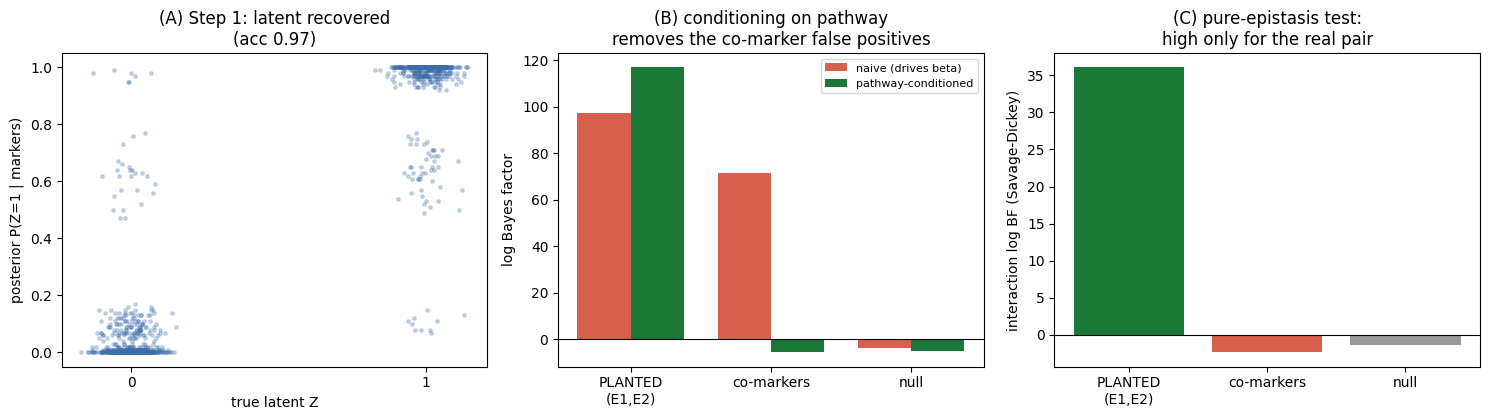

In [5]:
"""
Step 1 + Step 2 : a calibrated replacement for IBI-DT's beta
===========================================================
STEP 1  (joint latent inference, replaces the PC plug-in)
  A Bayesian 2-class latent measurement model, fit by Gibbs sampling, that
  infers the pathway state Z from the marker genes only (anchored to known
  pathway membership). It returns POSTERIOR DRAWS of Z, so its uncertainty is
  propagated downstream -- unlike the binarized-PC point estimate.

    Z_i ~ Bernoulli(pi)
    G_ij | Z_i ~ Bernoulli(theta_{j, Z_i})          (markers = anchored indicators)
    priors  pi ~ Beta(1,1),  theta_{jz} ~ Beta(1,1)

  Gibbs:  theta_{jz} | . ~ Beta(1+n1, 1+n0);  pi | . ~ Beta(...);
          Z_i | . ~ Bernoulli(sigmoid(log-odds from the markers)).
  Label-switching is fixed by orienting class 1 = high-marker class.

STEP 2  (pathway-conditioned interaction Bayes factor, integrated over p(Z|G))
  For a pair (a,b) we ask whether they explain T BEYOND the pathway:

     BF_path(a,b) =  E_{Z~p(Z|G)} ML(T | Z, G_a, G_b)
                    --------------------------------------
                     E_{Z~p(Z|G)} ML(T | Z)

  ML(.) is the IBI/BDeu marginal likelihood (uniform Dirichlet(1,1) per parent
  configuration -- the authors' convention). The expectation over Z draws
  propagates the latent's uncertainty. P(effect | D) = sigmoid(log BF).

  - For a TRUE epistatic pair, Z does not explain it -> BF large -> P ~ 1.
  - For two CO-MARKERS of the same pathway, conditioning on Z explains them
    away -> BF ~ 1 -> P ~ 0.5 (and below the naive, pathway-free BF).

  We also report a sharper, "pure-interaction" test: a Bayesian logistic
  Savage-Dickey Bayes factor on the G_a:G_b coefficient, on top of additive
  Z + G_a + G_b, again averaged over the Z posterior.

VALIDATION
  The generator plants ONE real AND-interaction (E1,E2, independent of the
  pathway) among the confounded co-markers, so we can check calibration:
  the method should fire on (E1,E2) and stay quiet on every co-marker pair,
  whereas the pathway-free statistic that drives IBI-DT's beta fires on both.
"""

import numpy as np
from scipy.special import gammaln, logsumexp, expit
rng = np.random.default_rng(3)

# ============================================================================
# IBI/BDeu marginal likelihood of T given discrete parents (authors' convention)
# ============================================================================
def lgml(T, config, K):
    """log ML of binary T given a parent configuration in {0..K-1};
       uniform Dirichlet(1,1) in each configuration (matches DriverSearch)."""
    out = 0.0
    for c in range(K):
        m = config == c
        N = int(m.sum())
        if N == 0:
            continue
        N1 = int(T[m].sum()); N0 = N - N1
        out += gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N0) + gammaln(1.0 + N1)
    return out

def lgml_noparent(T):
    N = len(T); N1 = int(T.sum()); N0 = N - N1
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N0) + gammaln(1.0 + N1)

# ============================================================================
# GENERATOR : latent pathway + co-markers (confounders) + 1 planted epistasis
# ============================================================================
n = 1200
m_mark = 6                       # co-markers of the latent pathway (confounders)
n_null = 18
Z_true = (rng.random(n) < 0.45).astype(int)          # latent pathway state

theta1, theta0 = 0.78, 0.15
G = np.zeros((n, m_mark), int)
for j in range(m_mark):
    G[:, j] = (rng.random(n) < np.where(Z_true == 1, theta1, theta0)).astype(int)

E1 = (rng.random(n) < 0.5).astype(int)               # planted epistasis pair
E2 = (rng.random(n) < 0.5).astype(int)               # independent of Z and each other
NULL = (rng.random((n, n_null)) < 0.25).astype(int)

# T depends on the pathway Z AND on the AND-interaction E1&E2 -- nothing else
b0, bZ, bE = -2.5, 3.0, 3.0
logitT = b0 + bZ * Z_true + bE * (E1 & E2)
T = (rng.random(n) < expit(logitT)).astype(int)

# convenient name -> column accessor
cols = {f"G{j+1}": G[:, j] for j in range(m_mark)}
cols["E1"] = E1; cols["E2"] = E2
for j in range(n_null):
    cols[f"N{j+1}"] = NULL[:, j]

# ============================================================================
# STEP 1 : Gibbs latent-class model on the markers (anchored)  -> Z posterior
# ============================================================================
def gibbs_lca(G, iters=1500, burn=500, thin=10, seed=1):
    rg = np.random.default_rng(seed)
    n, m = G.shape
    Z = (rg.random(n) < 0.5).astype(int)
    draws = []
    for it in range(iters):
        # theta_{j,z} | Z, G
        th = np.zeros((m, 2))
        for z in (0, 1):
            mask = Z == z
            nz = max(mask.sum(), 1)
            ones = G[mask].sum(0)
            th[:, z] = rg.beta(1 + ones, 1 + (mask.sum() - ones))
        pi = rg.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        # orient: class 1 = higher overall marker rate (kills label switching)
        if th[:, 1].sum() < th[:, 0].sum():
            th = th[:, ::-1]; pi = 1 - pi; Z = 1 - Z
        # Z_i | .
        lo = np.log(pi) - np.log(1 - pi)
        lo = lo + G @ (np.log(th[:, 1]) - np.log(th[:, 0]))
        lo = lo + (1 - G) @ (np.log(1 - th[:, 1]) - np.log(1 - th[:, 0]))
        Z = (rg.random(n) < expit(lo)).astype(int)
        if it >= burn and (it - burn) % thin == 0:
            draws.append(Z.copy())
    return np.array(draws)               # (S, n)

Zdraws = gibbs_lca(G)
S = len(Zdraws)
Zhat_mean = Zdraws.mean(0)
acc = max((Zdraws.mean(0).round() == Z_true).mean(),
          (Zdraws.mean(0).round() == 1 - Z_true).mean())
print(f"STEP 1  latent recovered: {S} posterior draws, "
      f"hard-assignment accuracy vs true Z = {acc:.3f}")

# ============================================================================
# STEP 2a : pathway-conditioned BDeu Bayes factor, integrated over p(Z|G)
# ============================================================================
def logmeanexp(x):
    return logsumexp(x) - np.log(len(x))

def bf_pathway(Va, Vb, Zdraws):
    """log BF that (Va,Vb) add anything to T BEYOND the pathway Z."""
    l1 = np.array([lgml(T, Zs + 2*Va + 4*Vb, 8) for Zs in Zdraws])   # T | Z,Va,Vb
    l0 = np.array([lgml(T, Zs,               2) for Zs in Zdraws])   # T | Z
    return logmeanexp(l1) - logmeanexp(l0)

def bf_naive(Va, Vb):
    """log BF that (Va,Vb) jointly explain T WITHOUT pathway control.
    This is the analytic stand-in for what IBI-DT's beta co-selection responds to."""
    return lgml(T, Va + 2*Vb, 4) - lgml_noparent(T)

# ============================================================================
# STEP 2b : sharper PURE-interaction test -- Bayesian logistic Savage-Dickey
#           on the Ga:Gb coefficient, on top of additive Z + Ga + Gb
# ============================================================================
def logistic_laplace(X, y, tau=4.0, iters=50):
    """IRLS MAP + Laplace covariance for logistic reg with N(0,tau^2) prior.
    returns (beta_hat, cov)."""
    n, d = X.shape
    beta = np.zeros(d); P = np.eye(d) / tau**2
    for _ in range(iters):
        eta = X @ beta; mu = expit(eta); W = mu * (1 - mu) + 1e-9
        grad = X.T @ (y - mu) - P @ beta
        H = X.T @ (X * W[:, None]) + P
        step = np.linalg.solve(H, grad)
        beta = beta + step
        if np.max(np.abs(step)) < 1e-8:
            break
    eta = X @ beta; mu = expit(eta); W = mu * (1 - mu) + 1e-9
    H = X.T @ (X * W[:, None]) + P
    cov = np.linalg.inv(H)
    return beta, cov

def normpdf(x, m, v):
    return np.exp(-0.5 * (x - m)**2 / v) / np.sqrt(2 * np.pi * v)

def bf_interaction(Va, Vb, Zdraws_sub, tau=4.0):
    """Savage-Dickey BF for the Va:Vb interaction term, beyond additive
    1 + Z + Va + Vb, averaged over the Z posterior."""
    bfs = []
    for Zs in Zdraws_sub:
        X = np.column_stack([np.ones(n), Zs, Va, Vb, Va * Vb]).astype(float)
        beta, cov = logistic_laplace(X, T, tau)
        m4, v4 = beta[4], cov[4, 4]                 # interaction coefficient
        post0 = normpdf(0.0, m4, v4)                # posterior density at 0
        prior0 = normpdf(0.0, 0.0, tau**2)          # prior density at 0
        bfs.append(prior0 / max(post0, 1e-300))     # BF_10 (evidence FOR interaction)
    return np.log(np.mean(bfs))

# ============================================================================
# evaluate on three categories of pairs
# ============================================================================
pairs = {
    "PLANTED epistasis (E1,E2)": [("E1", "E2")],
    "co-markers (confounded)":   [("G1", "G2"), ("G3", "G4"), ("G1", "G5"), ("G2", "G6")],
    "null pairs":                [("N1", "N2"), ("N3", "N4"), ("N5", "N6")],
    "control (E1, null)":        [("E1", "N7")],
}

Zsub = Zdraws[::3]      # fewer draws for the (heavier) logistic test
print("\n" + "=" * 78)
print(f"{'pair':26s}{'naive logBF':>13s}{'path logBF':>12s}"
      f"{'P(eff|path)':>13s}{'interaction logBF':>18s}")
print("  (naive = what beta responds to; path = conditioned on pathway Z)")
print("=" * 78)
for label, plist in pairs.items():
    print(f"-- {label}")
    for a, b in plist:
        Va, Vb = cols[a], cols[b]
        ln = bf_naive(Va, Vb)
        lp = bf_pathway(Va, Vb, Zdraws)
        pe = expit(lp)
        li = bf_interaction(Va, Vb, Zsub)
        print(f"   {a:3s}-{b:3s}{'':18s}{ln:>13.1f}{lp:>12.1f}{pe:>13.3f}{li:>18.1f}")

# ============================================================================
# figure
# ============================================================================
import matplotlib.pyplot as plt
cats = ["PLANTED\n(E1,E2)", "co-markers", "null"]
def collect(stat):
    out = []
    for plist in [pairs["PLANTED epistasis (E1,E2)"],
                  pairs["co-markers (confounded)"],
                  pairs["null pairs"]]:
        out.append([stat(cols[a], cols[b]) for a, b in plist])
    return out

naive = collect(lambda Va, Vb: bf_naive(Va, Vb))
path  = collect(lambda Va, Vb: bf_pathway(Va, Vb, Zdraws))
inter = collect(lambda Va, Vb: bf_interaction(Va, Vb, Zsub))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

# (A) latent recovery
ax[0].scatter(Z_true + rng.normal(0, .05, n), Zhat_mean, s=6, alpha=.25,
              color="#3b6dab")
ax[0].set_xlabel("true latent Z"); ax[0].set_ylabel("posterior P(Z=1 | markers)")
ax[0].set_title(f"(A) Step 1: latent recovered\n(acc {acc:.2f})")
ax[0].set_xticks([0, 1])

# (B) naive (drives beta) -- fires on BOTH epistasis and co-markers
means_n = [np.mean(v) for v in naive]
means_p = [np.mean(v) for v in path]
x = np.arange(3); w = 0.38
ax[1].bar(x - w/2, means_n, w, label="naive (drives beta)", color="#d6604d")
ax[1].bar(x + w/2, means_p, w, label="pathway-conditioned", color="#1b7837")
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(cats)
ax[1].set_ylabel("log Bayes factor"); ax[1].legend(fontsize=8)
ax[1].set_title("(B) conditioning on pathway\nremoves the co-marker false positives")

# (C) pure-interaction logistic BF -- calibrated separation
means_i = [np.mean(v) for v in inter]
ax[2].bar(x, means_i, color=["#1b7837", "#d6604d", "#999999"])
ax[2].axhline(0, color="k", lw=.8)
ax[2].set_xticks(x); ax[2].set_xticklabels(cats)
ax[2].set_ylabel("interaction log BF (Savage-Dickey)")
ax[2].set_title("(C) pure-epistasis test:\nhigh only for the real pair")

fig.tight_layout()
#fig.savefig("/mnt/user-data/outputs/step1_step2_calibrated_interaction.png", dpi=140)
print("\nsaved figure -> step1_step2_calibrated_interaction.png")

  dataset 1/30 done (1s)
  dataset 2/30 done (1s)
  dataset 3/30 done (2s)
  dataset 4/30 done (2s)
  dataset 5/30 done (3s)
  dataset 6/30 done (3s)
  dataset 7/30 done (4s)
  dataset 8/30 done (4s)
  dataset 9/30 done (5s)
  dataset 10/30 done (5s)
  dataset 11/30 done (6s)
  dataset 12/30 done (6s)
  dataset 13/30 done (4s)
  dataset 14/30 done (5s)
  dataset 15/30 done (5s)
  dataset 16/30 done (6s)
  dataset 17/30 done (6s)
  dataset 18/30 done (7s)
  dataset 19/30 done (7s)
  dataset 20/30 done (8s)
  dataset 21/30 done (8s)
  dataset 22/30 done (9s)
  dataset 23/30 done (9s)
  dataset 24/30 done (10s)
  dataset 25/30 done (10s)
  dataset 26/30 done (11s)
  dataset 27/30 done (11s)
  dataset 28/30 done (12s)
  dataset 29/30 done (13s)
  dataset 30/30 done (13s)

================  RESULTS  ================
pairs evaluated: 600  (150 true interactions, base rate 0.25 used as prior)
AUC   beta (IBI-DT)        = 0.703
AUC   naive interaction BF = 0.863
AUC   pathway interaction  = 0.

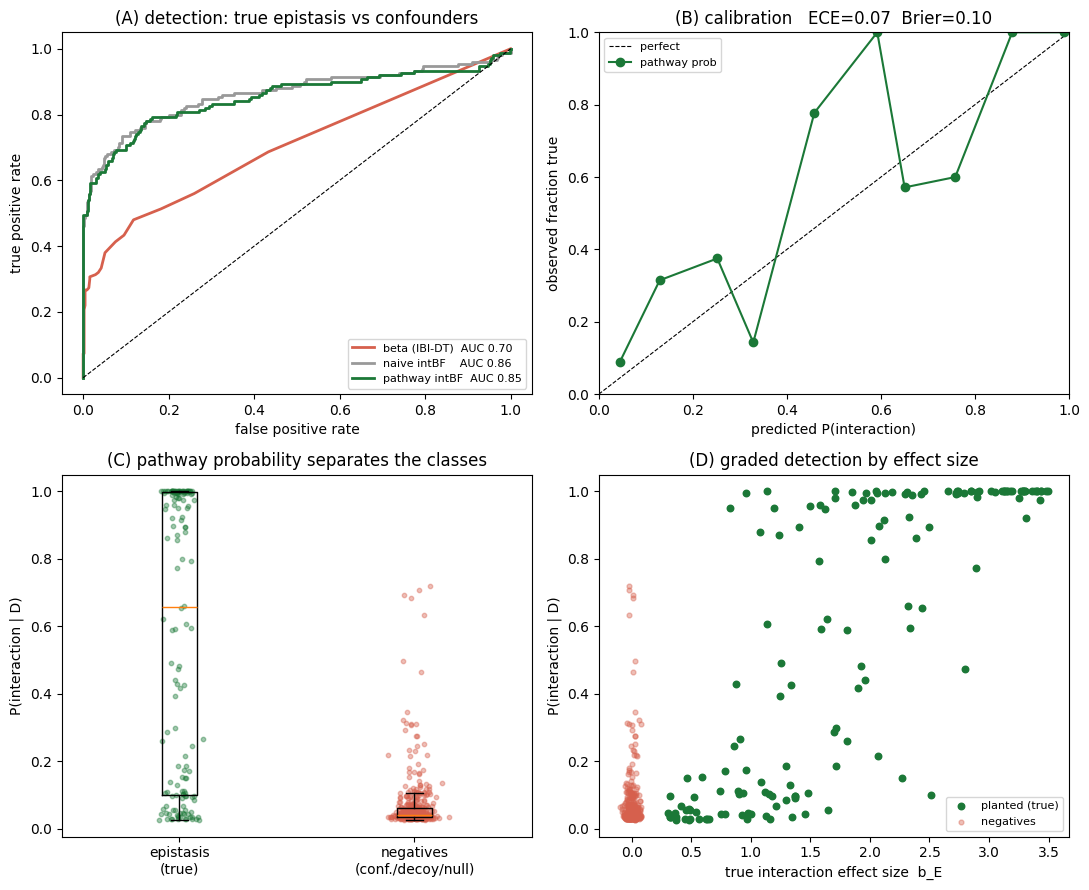

In [1]:
"""
CALIBRATION STUDY  (built from scratch, self-contained)
=======================================================
Question: is the pathway-conditioned interaction probability P(interaction | D)
CALIBRATED, and does it separate true epistasis from confounded co-markers
better than IBI-DT's beta?

Across many replicate datasets we plant REAL epistatic pairs at a RANGE of
effect sizes, mixed with three kinds of negatives:
  - co-marker pairs   : both genes read out the same latent pathway (confounded)
  - main-effect decoys: (a gene that has a main effect) x (a null gene)
  - null pairs        : two unrelated genes
Ground truth label = 1 only for a planted epistatic pair.

Three scores per candidate pair:
  (1) beta            : the real IBI-DT statistic (faithful tree ensemble)
  (2) naive intBF     : logistic interaction Bayes factor with NO pathway control
  (3) pathway intBF   : logistic interaction Bayes factor, additive Z1,Z2 latent
                        pathway states inferred by Gibbs, integrated over p(Z|G)
                        -> turned into a probability P = BF / (1 + BF)

Outputs: ROC + AUC (all three), reliability diagram + ECE + Brier for the
pathway probability, score-by-category, and P vs true effect size.

Marginal likelihoods use the authors' BDeu convention (uniform Dirichlet(1,1)
per parent configuration). The interaction test uses a Laplace log-evidence so
the Z-uncertainty is integrated properly (log-mean-exp over Z draws), not via a
point estimate.
"""

import numpy as np
from scipy.special import gammaln, logsumexp, expit
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import time

MASTER = np.random.default_rng(11)

# ----------------------------------------------------------------------------
# BDeu marginal likelihood (authors' convention) -- used by the faithful tree
# ----------------------------------------------------------------------------
def lgm_edge(T, Vmat):
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1 = T; t0 = 1 - T
    V1D1 = t1 @ Vmat;       V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat); V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for (a, b) in [(V0D0, V0D1), (V1D0, V1D1)]:
        lg += gammaln(2.0) - gammaln(2.0 + a + b)
        lg += gammaln(1.0 + a) + gammaln(1.0 + b)
    return lg

def lgm_noparent(T):
    N = len(T); N1 = int(T.sum()); N0 = N - N1
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N0) + gammaln(1.0 + N1)

# ----------------------------------------------------------------------------
# faithful IBI-DT tree + ensemble -> beta(pair)   (the published baseline)
# ----------------------------------------------------------------------------
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    usable = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not usable:
        paths.append(list(path)); return
    gains = lgm_edge(Tn, V[np.ix_(idx, usable)]) - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):
        child = idx[V[idx, s] == branch]
        if len(child):
            grow(T, V, child, cand, depth + 1, max_depth, neglogq, min_n,
                 used | {s}, path + [(s, branch)], paths)

def beta_ensemble(T, V, cand, N=40, max_depth=4, q=0.1, min_n=30, rg=None):
    rg = rg or np.random.default_rng(0)
    neglogq = -np.log(q)
    beta = {}
    i1all = np.where(T == 1)[0]; i0all = np.where(T == 0)[0]
    for _ in range(N):
        bs = np.concatenate([rg.choice(i0all, len(i0all), True),
                             rg.choice(i1all, len(i1all), True)])
        paths = []
        grow(T[bs], V[bs], np.arange(len(bs)), cand, 0, max_depth, neglogq,
             min_n, set(), [], paths)
        seen = set()
        for path in paths:
            vs = [v for v, _ in path]
            for x in range(len(vs)):
                for y in range(x + 1, len(vs)):
                    key = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if key not in seen:
                        beta[key] = beta.get(key, 0) + 1; seen.add(key)
    return beta

# ----------------------------------------------------------------------------
# STEP 1 : Gibbs latent-class pathway model (anchored), returns Z draws
# ----------------------------------------------------------------------------
def gibbs_lca(Gblock, n_draws=20, iters=900, burn=300, rg=None):
    rg = rg or np.random.default_rng(0)
    n, m = Gblock.shape
    Z = (rg.random(n) < 0.5).astype(int)
    draws = []; thin = max((iters - burn) // n_draws, 1)
    for it in range(iters):
        th = np.zeros((m, 2))
        for z in (0, 1):
            mask = Z == z; ones = Gblock[mask].sum(0)
            th[:, z] = rg.beta(1 + ones, 1 + (mask.sum() - ones))
        pi = rg.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th = th[:, ::-1]; pi = 1 - pi; Z = 1 - Z
        lo = (np.log(pi) - np.log(1 - pi)
              + Gblock @ (np.log(th[:, 1]) - np.log(th[:, 0]))
              + (1 - Gblock) @ (np.log(1 - th[:, 1]) - np.log(1 - th[:, 0])))
        Z = (rg.random(n) < expit(lo)).astype(int)
        if it >= burn and (it - burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)

# ----------------------------------------------------------------------------
# STEP 2 : interaction Bayes factor via Laplace log-evidence, integrated over Z
# ----------------------------------------------------------------------------
def logistic_logevidence(X, y, tau=4.0, iters=60):
    """Laplace approximation to log p(y | X) for logistic reg, prior N(0,tau^2)."""
    n, d = X.shape
    beta = np.zeros(d); Pi = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ beta); W = mu * (1 - mu) + 1e-9
        g = X.T @ (y - mu) - Pi @ beta
        H = X.T @ (X * W[:, None]) + Pi
        step = np.linalg.solve(H, g); beta += step
        if np.max(np.abs(step)) < 1e-8:
            break
    eta = X @ beta
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))          # log p(y|beta_hat)
    mu = expit(eta); W = mu * (1 - mu) + 1e-9
    H = X.T @ (X * W[:, None]) + Pi
    sign, logdetH = np.linalg.slogdet(H)
    logprior = -0.5 * d * np.log(tau**2) - 0.5 * (beta @ beta) / tau**2
    return ll + logprior - 0.5 * logdetH                   # (2pi terms cancel)

def logmeanexp(a):
    a = np.asarray(a); return logsumexp(a) - np.log(len(a))

def interaction_logBF(Ga, Gb, T, Zlist=None, tau=4.0):
    """log BF for the Ga:Gb interaction term, beyond additive [1,(Z..),Ga,Gb].
    If Zlist is given, integrate the Z-marginal evidence over the draws."""
    one = np.ones(len(T)); inter = (Ga * Gb).astype(float)
    if Zlist is None:
        base = [one, Ga, Gb]
        Xa = np.column_stack(base).astype(float)
        Xf = np.column_stack(base + [inter]).astype(float)
        return logistic_logevidence(Xf, T, tau) - logistic_logevidence(Xa, T, tau)
    ev_f, ev_a = [], []
    for Z in Zlist:                                        # Z is (n,K) pathway cols
        cols = [one] + [Z[:, k].astype(float) for k in range(Z.shape[1])] + [Ga, Gb]
        Xa = np.column_stack(cols).astype(float)
        Xf = np.column_stack(cols + [inter]).astype(float)
        ev_f.append(logistic_logevidence(Xf, T, tau))
        ev_a.append(logistic_logevidence(Xa, T, tau))
    return logmeanexp(ev_f) - logmeanexp(ev_a)

# ----------------------------------------------------------------------------
# GENERATOR : 2 latent pathways (confounders) + planted epistasis + nulls
# ----------------------------------------------------------------------------
def make_dataset(seed):
    rg = np.random.default_rng(seed)
    n = 900
    n_path, per = 2, 5                     # 2 pathways x 5 co-markers
    n_plant, n_null = 5, 10
    # Each marker is only WEAKLY informative on its own (0.62 vs 0.30) -- the
    # realistic case where no single gene defines the pathway, so the pathway is
    # identifiable only jointly. This is exactly the regime where a pathway-free
    # interaction test sees spurious AND-signal among co-markers.
    Z = [(rg.random(n) < 0.45).astype(int) for _ in range(n_path)]
    blocks = []
    for k in range(n_path):
        B = np.zeros((n, per), int)
        for j in range(per):
            B[:, j] = (rg.random(n) < np.where(Z[k] == 1, 0.62, 0.30)).astype(int)
        blocks.append(B)
    # planted epistasis genes (independent of pathways)
    E = (rg.random((n, 2 * n_plant)) < 0.5).astype(int)
    bE = rg.uniform(0.3, 3.5, n_plant)     # varied true effect sizes
    # nulls
    NU = (rg.random((n, n_null)) < 0.25).astype(int)
    # assemble full SGA matrix V and remember column roles
    V = np.hstack(blocks + [E, NU])
    off_block = [k * per for k in range(n_path)]
    Ecol0 = n_path * per
    Ncol0 = Ecol0 + 2 * n_plant
    # outcome: additive pathways + AND-interactions
    logit = -2.2
    for k in range(n_path):
        logit = logit + 3.0 * Z[k]
    for p in range(n_plant):
        a, b = Ecol0 + 2 * p, Ecol0 + 2 * p + 1
        logit = logit + bE[p] * (V[:, a] & V[:, b])
    T = (rg.random(n) < expit(logit)).astype(int)
    # candidate pairs with labels
    cands = []   # (i, j, label, effect)
    for p in range(n_plant):                              # positives
        cands.append((Ecol0 + 2*p, Ecol0 + 2*p + 1, 1, bE[p]))
    for k in range(n_path):                               # co-marker negatives
        base = off_block[k]
        for (x, y) in [(0, 1), (2, 3), (1, 4)]:
            cands.append((base + x, base + y, 0, 0.0))
    for p in range(min(4, n_plant)):                      # main-effect decoys
        cands.append((Ecol0 + 2*p, Ncol0 + p, 0, 0.0))
    for q in range(5):                                    # null pairs
        cands.append((Ncol0 + q, Ncol0 + q + 5 if q + 5 < n_null else Ncol0 + q, 0, 0.0))
    marker_cols = list(range(n_path * per))
    block_ids = [off_block, per]
    return V, T, Z, cands, marker_cols, n_path, per

# ----------------------------------------------------------------------------
# run the study
# ----------------------------------------------------------------------------
R = 30
rows = []   # (label, beta, naive_logBF, path_logBF, effect)
t0 = time.time()
for r in range(R):
    V, T, Ztrue, cands, marker_cols, n_path, per = make_dataset(1000 + r)
    rg = np.random.default_rng(5000 + r)
    # beta baseline (faithful IBI-DT)
    beta = beta_ensemble(T, V, list(range(V.shape[1])), N=40, rg=rg)
    # step 1: infer each pathway latent from its marker block (anchored)
    Zdraws = []
    for k in range(n_path):
        block = V[:, k*per:(k+1)*per]
        Zdraws.append(gibbs_lca(block, n_draws=18, rg=np.random.default_rng(9000+r*10+k)))
    S = min(len(z) for z in Zdraws)
    Zlist = [np.column_stack([Zdraws[k][s] for k in range(n_path)]) for s in range(S)]
    # step 2: scores per candidate pair
    for (i, j, lab, eff) in cands:
        Ga = V[:, i].astype(float); Gb = V[:, j].astype(float)
        b = beta.get((min(i, j), max(i, j)), 0)
        naive = interaction_logBF(Ga, Gb, T, Zlist=None)
        path = interaction_logBF(Ga, Gb, T, Zlist=Zlist)
        rows.append((lab, b, naive, path, eff))
    print(f"  dataset {r+1}/{R} done ({time.time()-t0:.0f}s)")

rows = np.array(rows, float)
lab = rows[:, 0]; beta_s = rows[:, 1]; naive_s = rows[:, 2]; path_s = rows[:, 3]; eff = rows[:, 4]
# BF -> probability using the screen's base rate as the prior odds (a tunable
# parameter set here to the true prevalence of interactions among candidates).
pi0 = lab.mean()
log_prior_odds = np.log(pi0 / (1 - pi0))
P_path = expit(path_s + log_prior_odds)

# ----------------------------------------------------------------------------
# metrics
# ----------------------------------------------------------------------------
def safe_auc(y, s):
    return roc_auc_score(y, s) if len(set(y)) == 2 else float("nan")

auc_beta  = safe_auc(lab, beta_s)
auc_naive = safe_auc(lab, naive_s)
auc_path  = safe_auc(lab, path_s)

# reliability (equal-width bins) + ECE + Brier for the pathway probability
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(P_path, bins) - 1, 0, 9)
conf, acc, wt = [], [], []
for bbin in range(10):
    m = idx == bbin
    if m.sum():
        conf.append(P_path[m].mean()); acc.append(lab[m].mean()); wt.append(m.sum())
conf, acc, wt = map(np.array, (conf, acc, wt))
ece = np.sum(wt * np.abs(acc - conf)) / wt.sum()
brier = np.mean((P_path - lab) ** 2)

print("\n================  RESULTS  ================")
print(f"pairs evaluated: {len(lab)}  ({int(lab.sum())} true interactions, "
      f"base rate {pi0:.2f} used as prior)")
print(f"AUC   beta (IBI-DT)        = {auc_beta:.3f}")
print(f"AUC   naive interaction BF = {auc_naive:.3f}")
print(f"AUC   pathway interaction  = {auc_path:.3f}")
print(f"pathway probability  ECE   = {ece:.3f}   Brier = {brier:.3f}")

# ----------------------------------------------------------------------------
# figure (2x2)
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(11, 9))

# (A) ROC
for s, name, c in [(beta_s, f"beta (IBI-DT)  AUC {auc_beta:.2f}", "#d6604d"),
                   (naive_s, f"naive intBF    AUC {auc_naive:.2f}", "#999999"),
                   (path_s, f"pathway intBF  AUC {auc_path:.2f}", "#1b7837")]:
    fpr, tpr, _ = roc_curve(lab, s)
    ax[0, 0].plot(fpr, tpr, color=c, lw=2, label=name)
ax[0, 0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0, 0].set_xlabel("false positive rate"); ax[0, 0].set_ylabel("true positive rate")
ax[0, 0].set_title("(A) detection: true epistasis vs confounders")
ax[0, 0].legend(fontsize=8, loc="lower right")

# (B) reliability diagram
ax[0, 1].plot([0, 1], [0, 1], "k--", lw=.8, label="perfect")
ax[0, 1].plot(conf, acc, "o-", color="#1b7837", label="pathway prob")
ax[0, 1].set_xlabel("predicted P(interaction)"); ax[0, 1].set_ylabel("observed fraction true")
ax[0, 1].set_title(f"(B) calibration   ECE={ece:.2f}  Brier={brier:.2f}")
ax[0, 1].legend(fontsize=8, loc="upper left")
ax[0, 1].set_xlim(0, 1); ax[0, 1].set_ylim(0, 1)

# (C) score by category
cats = {"epistasis\n(true)": lab == 1,
        "negatives\n(conf./decoy/null)": lab == 0}
data = [P_path[m] for m in cats.values()]
ax[1, 0].boxplot(data, tick_labels=list(cats.keys()), showfliers=False)
xs = {0: P_path[lab == 1], 1: P_path[lab == 0]}
for k, vals in xs.items():
    ax[1, 0].scatter(np.full(len(vals), k + 1) + MASTER.normal(0, .04, len(vals)),
                     vals, s=10, alpha=.4,
                     color="#1b7837" if k == 0 else "#d6604d")
ax[1, 0].set_ylabel("P(interaction | D)")
ax[1, 0].set_title("(C) pathway probability separates the classes")

# (D) probability vs true effect size (positives), negatives shown at 0
pos = lab == 1
ax[1, 1].scatter(eff[pos], P_path[pos], s=22, color="#1b7837", label="planted (true)")
ax[1, 1].scatter(np.zeros((lab == 0).sum()) + MASTER.normal(0, .03, (lab == 0).sum()),
                 P_path[lab == 0], s=12, alpha=.4, color="#d6604d", label="negatives")
ax[1, 1].set_xlabel("true interaction effect size  b_E")
ax[1, 1].set_ylabel("P(interaction | D)")
ax[1, 1].set_title("(D) graded detection by effect size")
ax[1, 1].legend(fontsize=8, loc="lower right")

fig.tight_layout()
#fig.savefig("/mnt/user-data/outputs/calibration_study.png", dpi=140)
print("saved figure -> calibration_study.png")

  [pairs] confound=0.2  done (7s)
  [pairs] confound=0.4  done (11s)
  [pairs] confound=0.6  done (18s)
  [pairs] confound=0.8  done (24s)
  [power] effect=0.8  done (31s)
  [power] effect=1.5  done (37s)
  [power] effect=2.2  done (41s)
  [power] effect=3.0  done (47s)

================  SUMMARY  ================
Interaction AUC by confounding strength:
  GWAS     0.2:0.93  0.4:0.88  0.6:0.91  0.8:0.85
  IBI-DT   0.2:0.72  0.4:0.64  0.6:0.64  0.8:0.58
  Pathway  0.2:0.91  0.4:0.86  0.6:0.91  0.8:0.87
Type I error on PHANTOM (co-marker) pairs by confounding strength:
  GWAS     0.2:0.01  0.4:0.01  0.6:0.17  0.8:0.12
  IBI-DT   0.2:0.01  0.4:0.06  0.6:0.19  0.8:0.09
  Pathway  0.2:0.03  0.4:0.04  0.6:0.11  0.8:0.07
Interaction power by effect size:
  GWAS     0.8:0.29  1.5:0.62  2.2:0.61  3.0:0.61
  IBI-DT   0.8:0.04  1.5:0.15  2.2:0.20  3.0:0.07
  Pathway  0.8:0.35  1.5:0.68  2.2:0.71  3.0:0.82
saved figure -> error_rate_study.png


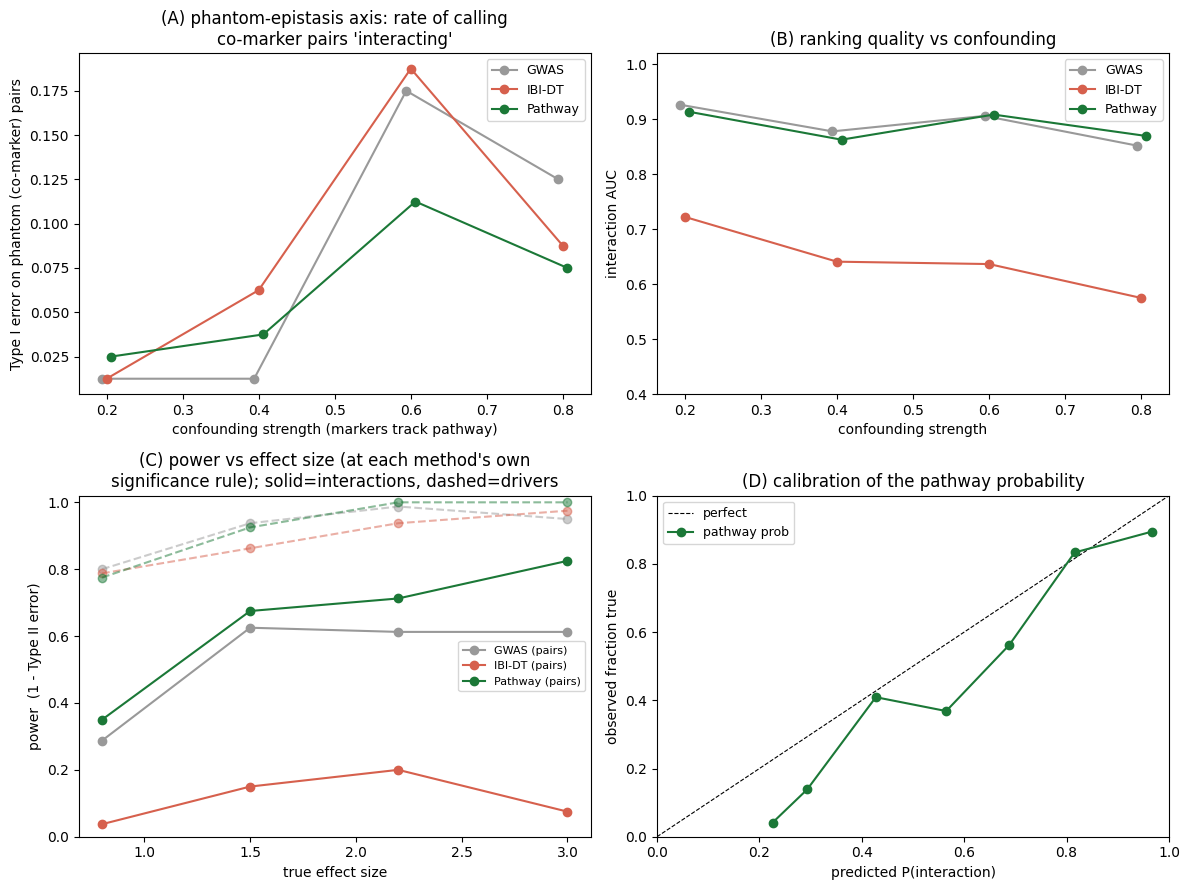

In [3]:
"""
Error-rate study: IBI-DT vs GWAS vs pathway-conditioned inference
================================================================
Measures Type I (false positive) and Type II (false negative) error for
SINGLE VARIANTS and for INTERACTIONS, across a controlled range of conditions,
for three methods:

  (1) IBI-DT      : the real alpha (drivers) and beta (interactions) from a
                    faithful tree ensemble, with the random-node null threshold.
  (2) GWAS        : the standard one-at-a-time baseline -- univariate logistic
                    per gene (drivers); logistic with a product term per pair
                    (interactions). No pathway, no joint model.
  (3) Pathway-cond: infer a hidden pathway state Z from its marker genes, then
                    test each gene / pair AFTER adding Z to the model
                    (conditioning), returning a calibrated probability.

ONE parametric generator with four knobs you can sweep:
    effect_size        -- strength of the planted true signals  (Type II axis)
    confound_strength  -- how tightly markers track the hidden pathway
                          (the phantom-epistasis axis -> interaction Type I)
    n                  -- sample size
    p_extra_nulls      -- number of unrelated null genes (multiplicity)

Outputs: Type I / Type II error and AUC per method, for variants and pairs,
plus a calibration (reliability) check for the pathway probability, and a
four-panel figure.  Self-contained; uses only numpy / scipy / sklearn / mpl.
"""

import numpy as np
from scipy.special import gammaln, expit, logsumexp
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import time

# ============================================================================
# ---- shared pieces -----------------------------------------------------------
# ============================================================================
def lgm_edge(T, Vmat):
    """IBI-DT marginal likelihood of edge V->T (authors' BDeu convention)."""
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1, t0 = T, 1 - T
    V1D1 = t1 @ Vmat;       V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat); V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for a, b in [(V0D0, V0D1), (V1D0, V1D1)]:
        lg += gammaln(2.0) - gammaln(2.0 + a + b) + gammaln(1.0 + a) + gammaln(1.0 + b)
    return lg

def lgm_noparent(T):
    N = len(T); N1 = int(T.sum())
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N - N1) + gammaln(1.0 + N1)

def logistic_logevidence(X, y, tau=4.0, iters=40):
    """Laplace approximation to log p(y|X) for logistic reg, prior N(0,tau^2)."""
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + P
        step = np.linalg.solve(H, X.T @ (y - mu) - P @ b); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    eta = X @ b; mu = expit(eta); W = mu * (1 - mu) + 1e-9
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))
    _, logdetH = np.linalg.slogdet(X.T @ (X * W[:, None]) + P)
    return ll - 0.5 * (b @ b) / tau**2 - 0.5 * logdetH

def logistic_wald_p(X, y, idx, iters=40):
    """p-value (Wald) for coefficient `idx` -- the GWAS-style test."""
    d = X.shape[1]; b = np.zeros(d)
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + 1e-6 * np.eye(d)
        step = np.linalg.solve(H, X.T @ (y - mu)); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
    cov = np.linalg.inv(X.T @ (X * W[:, None]) + 1e-9 * np.eye(d))
    z = b[idx] / np.sqrt(max(cov[idx, idx], 1e-12))
    from math import erfc, sqrt
    return erfc(abs(z) / sqrt(2))                       # two-sided p-value

# ============================================================================
# ---- STEP 1 : infer hidden pathway state Z from its markers ------------------
# ============================================================================
def infer_Z(G_block, n_draws=12, iters=500, burn=200, seed=0):
    rng = np.random.default_rng(seed)
    n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int)
    draws, thin = [], max((iters - burn) // n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0)
            th[:, z] = rng.beta(1 + on, 1 + ((Z == z).sum() - on))
        pi = rng.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th, pi, Z = th[:, ::-1], 1 - pi, 1 - Z
        lo = (np.log(pi / (1 - pi)) + G_block @ np.log(th[:, 1] / th[:, 0])
              + (1 - G_block) @ np.log((1 - th[:, 1]) / (1 - th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it - burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)

# ============================================================================
# ---- IBI-DT faithful tree + ensemble (for alpha / beta) ----------------------
# ============================================================================
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    usable = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not usable:
        paths.append(list(path)); return
    gains = lgm_edge(Tn, V[np.ix_(idx, usable)]) - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):
        child = idx[V[idx, s] == branch]
        if len(child):
            grow(T, V, child, cand, depth + 1, max_depth, neglogq, min_n,
                 used | {s}, path + [(s, branch)], paths)

def ibidt_alpha_beta(T, V, N=30, max_depth=4, q=0.1, min_n=25, rng=None):
    rng = rng or np.random.default_rng(0)
    p = V.shape[1]; cand = list(range(p)); neglogq = -np.log(q)
    alpha = np.zeros(p); beta = {}
    i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]
    def one_tree(Tb, Vb):
        paths = []
        grow(Tb, Vb, np.arange(len(Tb)), cand, 0, max_depth, neglogq, min_n, set(), [], paths)
        return paths
    a_null = b_null = 0
    for _ in range(N):
        bs = np.concatenate([rng.choice(i0, len(i0), True), rng.choice(i1, len(i1), True)])
        paths = one_tree(T[bs], V[bs])
        nodes = {v for pth in paths for v, _ in pth}
        for s in nodes:
            alpha[s] += 1
        seen = set()
        for pth in paths:
            vs = [v for v, _ in pth]
            for x in range(len(vs)):
                for y in range(x + 1, len(vs)):
                    k = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if k not in seen:
                        beta[k] = beta.get(k, 0) + 1; seen.add(k)
        # random-node null (keep shapes, random labels) -> thresholds
        ac, bc, bs2 = {}, {}, set()
        for pth in paths:
            rl = [int(rng.integers(p)) for _ in pth]
            for v in set(rl):
                ac[v] = ac.get(v, 0) + 1
            for x in range(len(rl)):
                for y in range(x + 1, len(rl)):
                    k = (min(rl[x], rl[y]), max(rl[x], rl[y]))
                    if k not in bs2:
                        bc[k] = bc.get(k, 0) + 1; bs2.add(k)
        a_null = max(a_null, max(ac.values()) if ac else 0)
        b_null = max(b_null, max(bc.values()) if bc else 0)
    return alpha, beta, a_null, b_null

# ============================================================================
# ---- THE GENERATOR : four knobs, known truth --------------------------------
# ============================================================================
def make_data(effect_size=2.0, confound_strength=0.55, n=700, p_extra_nulls=12,
              n_pathways=2, per=5, n_drivers=4, n_inter=4, seed=0):
    """Returns V (n x p), T, and ground-truth label sets for variants & pairs."""
    rng = np.random.default_rng(seed)
    theta1 = 0.5 + confound_strength / 2      # marker ON-rate when pathway ON
    theta0 = 0.5 - confound_strength / 2      # marker ON-rate when pathway OFF
    blocks, Zs = [], []
    for _ in range(n_pathways):
        Z = (rng.random(n) < 0.45).astype(int); Zs.append(Z)
        B = np.zeros((n, per), int)
        for j in range(per):
            B[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(int)
        blocks.append(B)
    # true single-variant drivers (independent of pathways)
    D = (rng.random((n, n_drivers)) < 0.30).astype(int)
    # true interaction genes (independent); each pair acts only via its product
    E = (rng.random((n, 2 * n_inter)) < 0.5).astype(int)
    # null genes
    NU = (rng.random((n, p_extra_nulls)) < 0.25).astype(int)

    V = np.hstack(blocks + [D, E, NU])
    off = {}
    c = 0
    for k in range(n_pathways): off[f"path{k}"] = c; c += per
    off["drv"] = c; c += n_drivers
    off["int"] = c; c += 2 * n_inter
    off["null"] = c

    logit = -2.0
    for Z in Zs:                                   # pathways act additively
        logit = logit + 2.2 * Z
    for d in range(n_drivers):                     # true main effects
        logit = logit + effect_size * D[:, d]
    for q in range(n_inter):                       # true interactions (AND only)
        a, b = off["int"] + 2*q, off["int"] + 2*q + 1
        logit = logit + effect_size * (V[:, a] & V[:, b])
    T = (rng.random(n) < expit(logit)).astype(int)

    # ground-truth labels
    true_drivers = set(range(off["drv"], off["drv"] + n_drivers))
    true_pairs = {(off["int"] + 2*q, off["int"] + 2*q + 1) for q in range(n_inter)}
    # candidate pools for evaluation
    driver_cands = list(range(off["drv"], off["drv"] + n_drivers)) + \
                   list(range(off["null"], off["null"] + min(8, p_extra_nulls)))
    # pair candidates: true pairs (pos) + co-marker pairs + null pairs (neg)
    pair_cands, pair_kinds = [], []
    for pr in true_pairs:
        pair_cands.append(pr); pair_kinds.append("pos")
    for k in range(n_pathways):
        b0 = off[f"path{k}"]
        for pr in [(b0+0, b0+1), (b0+2, b0+3)]:
            pair_cands.append(pr); pair_kinds.append("phantom")   # co-marker (confounded)
    nb = off["null"]
    for pr in [(nb+0, nb+1), (nb+2, nb+3), (nb+4, nb+5)]:
        pair_cands.append(pr); pair_kinds.append("null")
    return dict(V=V, T=T, Zs=Zs, off=off, per=per, n_pathways=n_pathways,
                true_drivers=true_drivers, true_pairs=set(true_pairs),
                driver_cands=driver_cands, pair_cands=pair_cands, pair_kinds=pair_kinds)

# ============================================================================
# ---- score one dataset with all three methods -------------------------------
# ============================================================================
def score_dataset(dat, rng):
    V, T = dat["V"], dat["T"]; n = len(T); one = np.ones(n)
    # ---- IBI-DT
    alpha, beta, a_null, b_null = ibidt_alpha_beta(T, V, rng=rng)
    # ---- pathway latent (infer Z per pathway, pair the draws)
    Zd = [infer_Z(V[:, dat["off"][f"path{k}"]:dat["off"][f"path{k}"]+dat["per"]],
                  seed=int(rng.integers(1e9))) for k in range(dat["n_pathways"])]
    S = min(len(z) for z in Zd)
    Zlist = [np.column_stack([Zd[k][s] for k in range(dat["n_pathways"])]) for s in range(S)]

    rows_drv, rows_pair, kinds_out = [], [], []
    # ---------- DRIVERS ----------
    for g in dat["driver_cands"]:
        lab = int(g in dat["true_drivers"])
        Gg = V[:, g].astype(float)
        # GWAS: univariate logistic Wald p (score = -log p, higher = more sig)
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Gg]), T, 1), 1e-300))
        # IBI-DT: alpha, relative to its random-node null
        ibidt = alpha[g] - a_null
        # pathway-conditioned: BF of adding G beyond Z  -> log BF
        ev0, ev1 = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k].astype(float) for k in range(Z.shape[1])])
            ev0.append(logistic_logevidence(base, T))
            ev1.append(logistic_logevidence(np.column_stack([base, Gg]), T))
        pcond = (logsumexp(ev1) - logsumexp(ev0))
        rows_drv.append((lab, gwas, ibidt, pcond))
    # ---------- PAIRS ----------
    for (a, b), kind in zip(dat["pair_cands"], dat["pair_kinds"]):
        lab = int(kind == "pos")
        Ga, Gb = V[:, a].astype(float), V[:, b].astype(float); inter = Ga * Gb
        # GWAS: product-term Wald p in logistic T ~ Ga+Gb+Ga*Gb
        Xg = np.column_stack([one, Ga, Gb, inter])
        gwas = -np.log(max(logistic_wald_p(Xg, T, 3), 1e-300))
        # IBI-DT: beta, relative to its random-node null
        ibidt = beta.get((min(a, b), max(a, b)), 0) - b_null
        # pathway-conditioned: BF of the product term beyond Z+Ga+Gb
        ev_add, ev_int = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k].astype(float) for k in range(Z.shape[1])] + [Ga, Gb])
            ev_add.append(logistic_logevidence(base, T))
            ev_int.append(logistic_logevidence(np.column_stack([base, inter]), T))
        pcond = (logsumexp(ev_int) - logsumexp(ev_add))
        rows_pair.append((lab, gwas, ibidt, pcond)); kinds_out.append(kind)
    return rows_drv, rows_pair, kinds_out

# ============================================================================
# ---- run sweeps -------------------------------------------------------------
# ============================================================================
def auc(labels, scores):
    return roc_auc_score(labels, scores) if len(set(labels)) == 2 else np.nan

def collect(rows):
    a = np.array(rows, float)
    return a[:, 0], a[:, 1], a[:, 2], a[:, 3]   # label, gwas, ibidt, pcond

t0 = time.time()
R = 20                                           # replicate datasets per condition

# Each method's OWN native significance rule (so Type I / power are interpretable):
#   GWAS    : p < 0.05            -> score = -log p   >= -log(0.05)
#   IBI-DT  : beta > random-null  -> score = beta - b_null  >= 1   (use 0.5)
#   Pathway : Bayes factor > 3    -> score = log BF   >= log 3   ("substantial")
NATIVE_THR = {"GWAS": -np.log(0.05), "IBI-DT": 0.5, "Pathway": np.log(3.0)}

# ---- SWEEP 1: confounding strength (the phantom-epistasis axis), pairs -------
conf_grid = [0.2, 0.4, 0.6, 0.8]
pair_auc = {m: [] for m in ["GWAS", "IBI-DT", "Pathway"]}
pair_typeI = {m: [] for m in ["GWAS", "IBI-DT", "Pathway"]}
for cs in conf_grid:
    lab_all, g_all, i_all, p_all, k_all = [], [], [], [], []
    for r in range(R):
        dat = make_data(effect_size=2.0, confound_strength=cs, n=700, seed=100*r + int(cs*10))
        _, rp, pk = score_dataset(dat, np.random.default_rng(7000 + r))
        L, G, I, P = collect(rp)
        lab_all += list(L); g_all += list(G); i_all += list(I); p_all += list(P); k_all += list(pk)
    lab_all = np.array(lab_all); k_all = np.array(k_all)
    phantom = k_all == "phantom"                      # Type I measured on co-marker pairs
    for name, sc in [("GWAS", np.array(g_all)), ("IBI-DT", np.array(i_all)), ("Pathway", np.array(p_all))]:
        pair_auc[name].append(auc(lab_all, sc))
        pair_typeI[name].append(float(np.mean(sc[phantom] >= NATIVE_THR[name])))
    print(f"  [pairs] confound={cs}  done ({time.time()-t0:.0f}s)")

# ---- SWEEP 2: effect size (power / Type II), pairs and drivers ---------------
eff_grid = [0.8, 1.5, 2.2, 3.0]
pair_power = {m: [] for m in ["GWAS", "IBI-DT", "Pathway"]}
drv_power = {m: [] for m in ["GWAS", "IBI-DT", "Pathway"]}
calib_pred, calib_lab = [], []                   # for the reliability panel (Pathway, pairs)
for es in eff_grid:
    Lp, Gp, Ip, Pp = [], [], [], []
    Ld, Gd, Id, Pd = [], [], [], []
    for r in range(R):
        dat = make_data(effect_size=es, confound_strength=0.55, n=700, seed=200*r + int(es*10))
        rd, rp, _ = score_dataset(dat, np.random.default_rng(8000 + r))
        L, G, I, P = collect(rp); Lp += list(L); Gp += list(G); Ip += list(I); Pp += list(P)
        L2, G2, I2, P2 = collect(rd); Ld += list(L2); Gd += list(G2); Id += list(I2); Pd += list(P2)
        if abs(es - 2.2) < 1e-6:                  # collect calibration at one effect size
            calib_pred += list(expit(np.array(P) + np.log(0.3/0.7))); calib_lab += list(L)
    Lp = np.array(Lp); Ld = np.array(Ld)
    for name, scp, scd in [("GWAS", Gp, Gd), ("IBI-DT", Ip, Id), ("Pathway", Pp, Pd)]:
        scp, scd = np.array(scp), np.array(scd)
        thr = NATIVE_THR[name]                       # power = TPR at the native significance rule
        pair_power[name].append(float(np.mean(scp[Lp == 1] >= thr)) if (Lp == 1).any() else np.nan)
        drv_power[name].append(float(np.mean(scd[Ld == 1] >= thr)) if (Ld == 1).any() else np.nan)
    print(f"  [power] effect={es}  done ({time.time()-t0:.0f}s)")

# ============================================================================
# ---- figure -----------------------------------------------------------------
# ============================================================================
col = {"GWAS": "#999999", "IBI-DT": "#d6604d", "Pathway": "#1b7837"}
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# (A) interaction Type I error vs confounding strength
jit = {"GWAS": -0.006, "IBI-DT": 0.0, "Pathway": 0.006}
for m in col:
    ax[0, 0].plot(np.array(conf_grid)+jit[m], pair_typeI[m], "o-", color=col[m], label=m)
ax[0, 0].set_xlabel("confounding strength (markers track pathway)")
ax[0, 0].set_ylabel("Type I error on phantom (co-marker) pairs")
ax[0, 0].set_title("(A) phantom-epistasis axis: rate of calling\nco-marker pairs 'interacting'")
ax[0, 0].legend(fontsize=9)

# (B) interaction AUC vs confounding strength
for m in col:
    ax[0, 1].plot(np.array(conf_grid)+jit[m], pair_auc[m], "o-", color=col[m], label=m)
ax[0, 1].set_xlabel("confounding strength")
ax[0, 1].set_ylabel("interaction AUC")
ax[0, 1].set_title("(B) ranking quality vs confounding")
ax[0, 1].legend(fontsize=9); ax[0, 1].set_ylim(0.4, 1.02)

# (C) power (1 - Type II) vs effect size, at fixed ~10% false-positive rate
for m in col:
    ax[1, 0].plot(eff_grid, pair_power[m], "o-", color=col[m], label=f"{m} (pairs)")
    ax[1, 0].plot(eff_grid, drv_power[m], "o--", color=col[m], alpha=.5)
ax[1, 0].set_xlabel("true effect size")
ax[1, 0].set_ylabel("power  (1 - Type II error)")
ax[1, 0].set_title("(C) power vs effect size (at each method's own\nsignificance rule); solid=interactions, dashed=drivers")
ax[1, 0].legend(fontsize=8); ax[1, 0].set_ylim(0, 1.02)

# (D) calibration of the pathway interaction probability
calib_pred, calib_lab = np.array(calib_pred), np.array(calib_lab)
bins = np.linspace(0, 1, 9); idx = np.clip(np.digitize(calib_pred, bins) - 1, 0, 7)
conf, accs = [], []
for bb in range(8):
    mm = idx == bb
    if mm.sum() >= 3:
        conf.append(calib_pred[mm].mean()); accs.append(calib_lab[mm].mean())
ax[1, 1].plot([0, 1], [0, 1], "k--", lw=.8, label="perfect")
ax[1, 1].plot(conf, accs, "o-", color="#1b7837", label="pathway prob")
ax[1, 1].set_xlabel("predicted P(interaction)"); ax[1, 1].set_ylabel("observed fraction true")
ax[1, 1].set_title("(D) calibration of the pathway probability")
ax[1, 1].legend(fontsize=9); ax[1, 1].set_xlim(0, 1); ax[1, 1].set_ylim(0, 1)

fig.tight_layout()
fig.savefig("error_rate_study.png", dpi=140)

print("\n================  SUMMARY  ================")
print("Interaction AUC by confounding strength:")
for m in col:
    print(f"  {m:8s}", "  ".join(f"{cs}:{a:.2f}" for cs, a in zip(conf_grid, pair_auc[m])))
print("Type I error on PHANTOM (co-marker) pairs by confounding strength:")
for m in col:
    print(f"  {m:8s}", "  ".join(f"{cs}:{e:.2f}" for cs, e in zip(conf_grid, pair_typeI[m])))
print("Interaction power by effect size:")
for m in col:
    print(f"  {m:8s}", "  ".join(f"{es}:{a:.2f}" for es, a in zip(eff_grid, pair_power[m])))
print("saved figure -> error_rate_study.png")

  [binary] confound=0.2 done (4s)
  [binary] confound=0.4 done (9s)
  [binary] confound=0.6 done (13s)
  [binary] confound=0.8 done (18s)
  [binary] effect=0.8 done (23s)
  [binary] effect=1.5 done (27s)
  [binary] effect=2.2 done (32s)
  [binary] effect=3.0 done (36s)
  [continuous] confound=0.2 done (40s)
  [continuous] confound=0.4 done (44s)
  [continuous] confound=0.6 done (48s)
  [continuous] confound=0.8 done (52s)
  [continuous] effect=0.8 done (56s)
  [continuous] effect=1.5 done (60s)
  [continuous] effect=2.2 done (64s)
  [continuous] effect=3.0 done (68s)

================ SUMMARY ================

--- BINARY latent ---
interaction AUC      : {'GWAS': [0.94, 0.95, 0.91, 0.93], 'IBI-DT': [0.73, 0.68, 0.64, 0.59], 'Pathway': [0.94, 0.95, 0.93, 0.93]}
interaction Type I   : {'GWAS': [0.0, 0.03, 0.2, 0.09], 'IBI-DT': [0.03, 0.08, 0.12, 0.08], 'Pathway': [0.03, 0.08, 0.11, 0.09]}
DRIVER Type I        : {'GWAS': [0.11, 0.56, 0.81, 1.0], 'IBI-DT': [0.14, 0.39, 0.41, 0.48], 'Pathwa

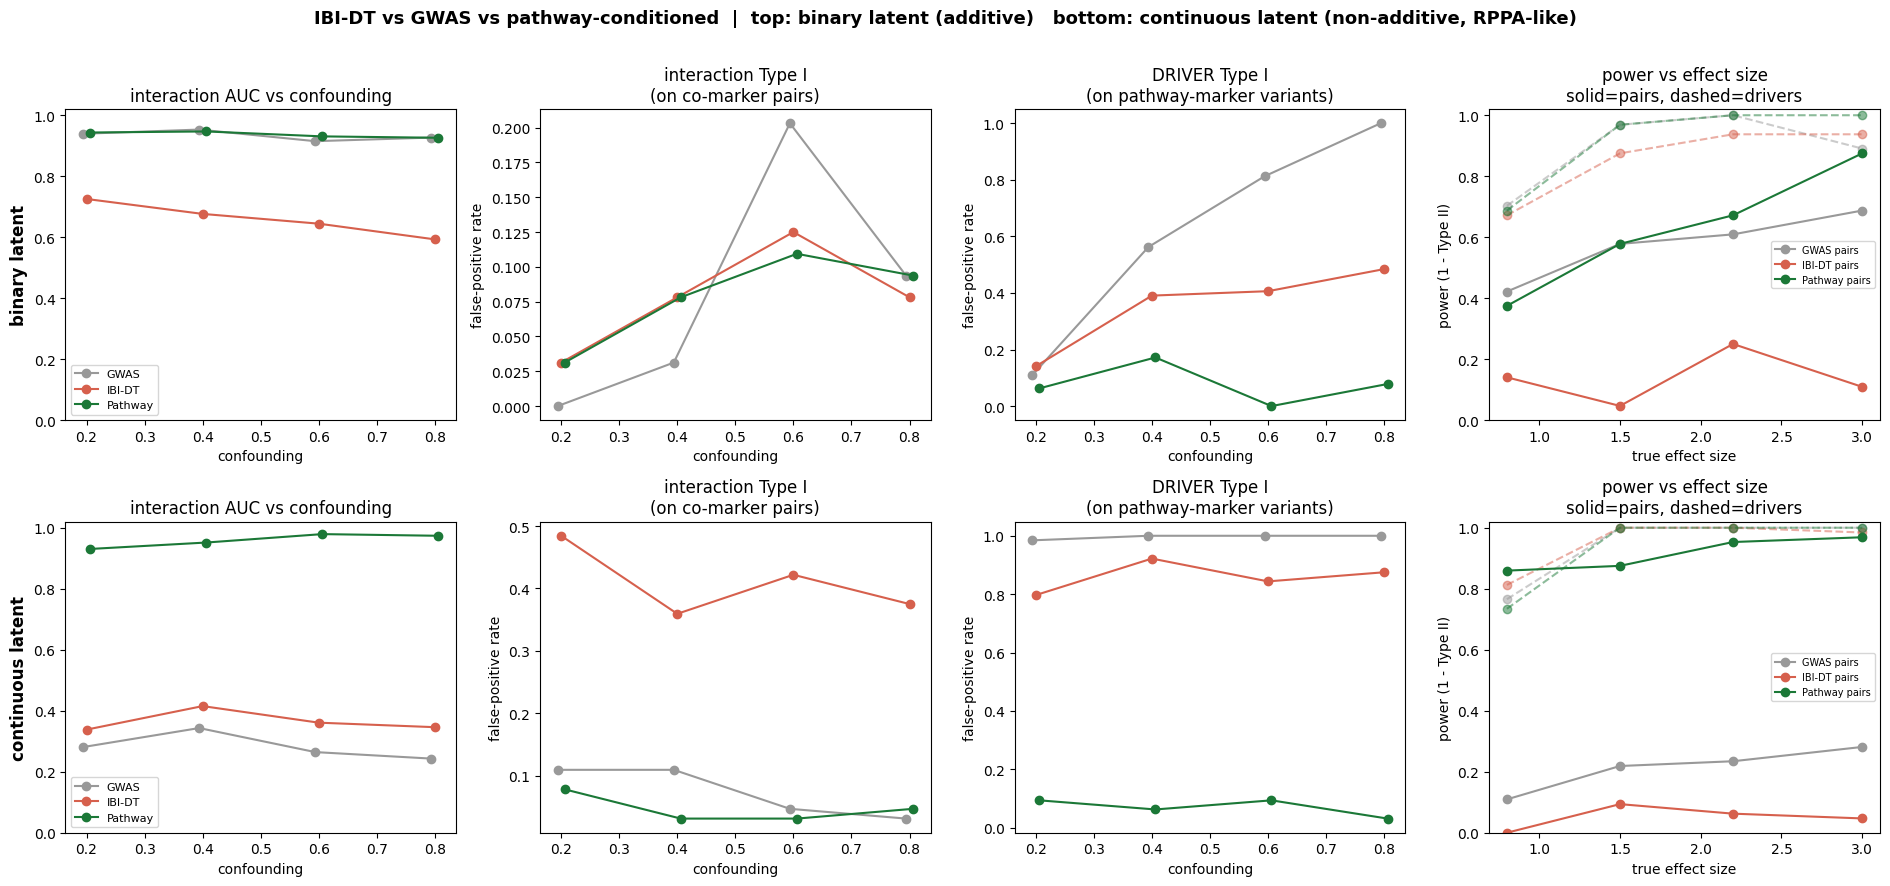

In [7]:
"""
Error-rate study v2: drivers AND interactions, binary vs continuous latent
==========================================================================
Same generator family as before (hidden pathway -> marker genes -> outcome T),
now with two additions you asked for:

  1) DRIVER Type I / Type II, not just interactions. Single-variant detection
     is the alpha side of IBI-DT, and it is exactly where additive confounding
     inflates marginal tests -- so it is where conditioning on the pathway helps
     most. We report driver false-positive rate on null variants and power.

  2) A CONTINUOUS-LATENT variant. Biologically: a pathway is not an on/off
     switch but an ACTIVITY LEVEL, and its read-outs are continuous protein /
     expression measurements (think RPPA). Mathematically this is the regime
     where the shared latent leaks a spurious PRODUCT term into the outcome
     (phantom epistasis for interactions), so conditioning on the inferred
     latent should pull clearly ahead of a plain product-term (GWAS) test.

       binary latent     : Z in {0,1}, markers Bernoulli(theta_z)   -> additive
       continuous latent : Z ~ N(0,1), markers G = lambda*Z + noise -> NOT additive

Three method arms throughout:
   GWAS     : one-at-a-time. Marginal logistic per variant (drivers);
              logistic with a product term per pair (interactions).
   IBI-DT   : faithful tree ensemble -> alpha (drivers), beta (interactions),
              with the random-node null as the significance threshold.
   Pathway  : infer the latent pathway state from its markers (Gibbs latent
              class for binary; Gaussian factor model for continuous), then
              test each variant / pair AFTER conditioning on it; calibrated.

Method lineage (NOT invented here): latent-confounder adjustment = SVA / PEER /
RUV; Bayesian null/main/interaction partition = BEAM; the failure mode = phantom
epistasis. Contribution here is the diagnosis + pathway-anchored assembly.

Self-contained: numpy / scipy / sklearn / matplotlib.
"""

import numpy as np
from scipy.special import gammaln, expit, logsumexp
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import time

# ============================================================================
# shared marginal-likelihood / evidence pieces
# ============================================================================
def lgm_edge(T, Vmat):
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1, t0 = T, 1 - T
    V1D1 = t1 @ Vmat; V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat); V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for a, b in [(V0D0, V0D1), (V1D0, V1D1)]:
        lg += gammaln(2.0) - gammaln(2.0 + a + b) + gammaln(1.0 + a) + gammaln(1.0 + b)
    return lg

def lgm_noparent(T):
    N = len(T); N1 = int(T.sum())
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N - N1) + gammaln(1.0 + N1)

def logistic_logevidence(X, y, tau=4.0, iters=40):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + P
        step = np.linalg.solve(H, X.T @ (y - mu) - P @ b); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    eta = X @ b; mu = expit(eta); W = mu * (1 - mu) + 1e-9
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))
    _, logdetH = np.linalg.slogdet(X.T @ (X * W[:, None]) + P)
    return ll - 0.5 * (b @ b) / tau**2 - 0.5 * logdetH

def logistic_wald_p(X, y, idx, iters=40):
    from math import erfc, sqrt
    d = X.shape[1]; b = np.zeros(d)
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + 1e-6 * np.eye(d)
        step = np.linalg.solve(H, X.T @ (y - mu)); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
    cov = np.linalg.inv(X.T @ (X * W[:, None]) + 1e-9 * np.eye(d))
    z = b[idx] / np.sqrt(max(cov[idx, idx], 1e-12))
    return erfc(abs(z) / sqrt(2))

# ============================================================================
# STEP 1 -- infer the latent, TWO versions
# ============================================================================
def infer_Z_binary(G_block, n_draws=12, iters=500, burn=200, seed=0):
    """Gibbs latent-class model for BINARY markers -> posterior draws of Z in {0,1}."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int); draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0)
            th[:, z] = rng.beta(1 + on, 1 + ((Z == z).sum() - on))
        pi = rng.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th, pi, Z = th[:, ::-1], 1 - pi, 1 - Z
        lo = (np.log(pi/(1-pi)) + G_block @ np.log(th[:, 1]/th[:, 0])
              + (1 - G_block) @ np.log((1-th[:, 1])/(1-th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.astype(float).copy())
    return np.array(draws)

def infer_Z_continuous(G_block, n_draws=12, iters=400, burn=150, seed=0):
    """One-factor Gaussian factor model for CONTINUOUS markers (RPPA-style):
       G_j = lambda_j * Z + noise.  Gibbs -> posterior draws of the factor Z (real)."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    G = (G_block - G_block.mean(0)) / (G_block.std(0) + 1e-9)
    lam = np.ones(m); psi = np.ones(m); Z = rng.standard_normal(n)
    draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        # Z_i | . ~ N(mu_i, v)   (posterior of the factor score)
        v = 1.0 / (1.0 + np.sum(lam**2 / psi))
        mu = v * (G @ (lam / psi))
        Z = mu + np.sqrt(v) * rng.standard_normal(n)
        # lambda_j | . ~ N(.,.)   (regress each marker on Z)
        zz = Z @ Z + 1e-6
        for j in range(m):
            mlam = (G[:, j] @ Z) / zz; vlam = psi[j] / zz
            lam[j] = mlam + np.sqrt(vlam) * rng.standard_normal()
        # psi_j | . ~ InvGamma  (residual variance)
        resid = G - np.outer(Z, lam)
        psi = (np.sum(resid**2, 0) + 1.0) / rng.chisquare(n + 2, size=m)
        if lam.sum() < 0:                    # fix sign (identifiability)
            lam, Z = -lam, -Z
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)                   # real-valued factor scores

# ============================================================================
# IBI-DT faithful tree + ensemble (binary inputs; for continuous markers we
# binarise at the median so IBI-DT still has something to split on, as a user
# would have to do in practice)
# ============================================================================
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    usable = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not usable:
        paths.append(list(path)); return
    gains = lgm_edge(Tn, V[np.ix_(idx, usable)]) - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):
        child = idx[V[idx, s] == branch]
        if len(child):
            grow(T, V, child, cand, depth+1, max_depth, neglogq, min_n,
                 used | {s}, path + [(s, branch)], paths)

def ibidt_alpha_beta(T, Vbin, N=30, max_depth=4, q=0.1, min_n=25, rng=None):
    rng = rng or np.random.default_rng(0)
    p = Vbin.shape[1]; cand = list(range(p)); neglogq = -np.log(q)
    alpha = np.zeros(p); beta = {}; i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]
    a_null = b_null = 0
    for _ in range(N):
        bs = np.concatenate([rng.choice(i0, len(i0), True), rng.choice(i1, len(i1), True)])
        paths = []
        grow(T[bs], Vbin[bs], np.arange(len(bs)), cand, 0, max_depth, neglogq, min_n, set(), [], paths)
        nodes = {v for pth in paths for v, _ in pth}
        for s in nodes: alpha[s] += 1
        seen = set()
        for pth in paths:
            vs = [v for v, _ in pth]
            for x in range(len(vs)):
                for y in range(x+1, len(vs)):
                    k = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if k not in seen: beta[k] = beta.get(k, 0)+1; seen.add(k)
        ac, bc, bs2 = {}, {}, set()
        for pth in paths:
            rl = [int(rng.integers(p)) for _ in pth]
            for v in set(rl): ac[v] = ac.get(v, 0)+1
            for x in range(len(rl)):
                for y in range(x+1, len(rl)):
                    k = (min(rl[x], rl[y]), max(rl[x], rl[y]))
                    if k not in bs2: bc[k] = bc.get(k, 0)+1; bs2.add(k)
        a_null = max(a_null, max(ac.values()) if ac else 0)
        b_null = max(b_null, max(bc.values()) if bc else 0)
    return alpha, beta, a_null, b_null

# ============================================================================
# GENERATOR -- one function, switchable latent type
# ============================================================================
def make_data(effect_size=2.0, confound_strength=0.55, n=700, p_extra_nulls=12,
              n_pathways=2, per=5, n_drivers=4, n_inter=4, latent="binary", seed=0):
    rng = np.random.default_rng(seed)
    blocks, Zs = [], []
    for _ in range(n_pathways):
        if latent == "binary":
            Z = (rng.random(n) < 0.45).astype(float)
            theta1, theta0 = 0.5 + confound_strength/2, 0.5 - confound_strength/2
            B = np.zeros((n, per))
            for j in range(per):
                B[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(float)
        else:  # continuous: pathway ACTIVITY level; markers are noisy linear read-outs (RPPA-like)
            Z = rng.standard_normal(n)
            lam = 0.5 + confound_strength            # loading grows with confounding
            noise = np.sqrt(max(1.0 - 0.0, 0.3))
            B = lam * Z[:, None] + noise * rng.standard_normal((n, per))
        Zs.append(Z); blocks.append(B)

    D = (rng.random((n, n_drivers)) < 0.30).astype(float)        # true single-variant drivers
    E = (rng.random((n, 2*n_inter)) < 0.5).astype(float)         # true interaction genes
    NU = (rng.random((n, p_extra_nulls)) < 0.25).astype(float)   # nulls
    V = np.hstack(blocks + [D, E, NU])

    off = {}; c = 0
    for k in range(n_pathways): off[f"path{k}"] = c; c += per
    off["drv"] = c; c += n_drivers
    off["int"] = c; c += 2*n_inter
    off["null"] = c

    logit = -2.0
    for Z in Zs:
        logit = logit + (2.2 * Z if latent == "binary" else 1.6 * Z)   # pathway acts additively
    for d in range(n_drivers):
        logit = logit + effect_size * D[:, d]
    for q in range(n_inter):
        a, b = off["int"]+2*q, off["int"]+2*q+1
        logit = logit + effect_size * ((V[:, a] > 0.5) & (V[:, b] > 0.5)).astype(float)
    T = (rng.random(n) < expit(logit)).astype(int)

    # binarised copy of the SGA matrix for IBI-DT and as the 0/1 'genotype' for GWAS/pathway
    Vbin = (V > np.median(V, 0)).astype(float) if latent == "continuous" else V.copy()
    # for marker columns keep the binary draws when binary; for continuous, median-split
    marker_cols = list(range(n_pathways*per))

    true_drivers = set(range(off["drv"], off["drv"]+n_drivers))
    true_pairs = {(off["int"]+2*q, off["int"]+2*q+1) for q in range(n_inter)}
    marker_pick = [off["path0"]+0, off["path0"]+1] + \
                  ([off["path1"]+0, off["path1"]+1] if n_pathways > 1 else [])
    driver_cands = [(g, "pos") for g in range(off["drv"], off["drv"]+n_drivers)] + \
                   [(g, "null") for g in range(off["null"], off["null"]+min(6, p_extra_nulls))] + \
                   [(g, "phantom") for g in marker_pick]   # correlate with T via pathway only
    pair_cands = [(pr, "pos") for pr in true_pairs]
    for k in range(n_pathways):
        b0 = off[f"path{k}"]
        pair_cands += [((b0+0, b0+1), "phantom"), ((b0+2, b0+3), "phantom")]
    nb = off["null"]
    pair_cands += [((nb+0, nb+1), "null"), ((nb+2, nb+3), "null"), ((nb+4, nb+5), "null")]
    return dict(V=V, Vbin=Vbin, T=T, off=off, per=per, n_pathways=n_pathways, latent=latent,
                true_drivers=true_drivers, true_pairs=true_pairs,
                driver_cands=driver_cands, pair_cands=pair_cands, marker_cols=marker_cols)

# ============================================================================
# score one dataset with all three methods (drivers + pairs)
# ============================================================================
def score_dataset(dat, rng):
    V, Vbin, T = dat["V"], dat["Vbin"], dat["T"]; n = len(T); one = np.ones(n)
    alpha, beta, a_null, b_null = ibidt_alpha_beta(T, Vbin, rng=rng)
    infer = infer_Z_binary if dat["latent"] == "binary" else infer_Z_continuous
    Zd = [infer(dat["V"][:, dat["off"][f"path{k}"]:dat["off"][f"path{k}"]+dat["per"]],
                seed=int(rng.integers(1e9))) for k in range(dat["n_pathways"])]
    S = min(len(z) for z in Zd)
    Zlist = [np.column_stack([Zd[k][s] for k in range(dat["n_pathways"])]) for s in range(S)]

    # ---- drivers: returns rows (label, gwas, ibidt, pcond) + kind
    drv_rows, drv_kind = [], []
    for g, kind in dat["driver_cands"]:
        lab = int(kind == "pos"); Gg = Vbin[:, g].astype(float)
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Gg]), T, 1), 1e-300))
        ibidt = alpha[g] - a_null
        ev0, ev1 = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])])
            ev0.append(logistic_logevidence(base, T))
            ev1.append(logistic_logevidence(np.column_stack([base, Gg]), T))
        drv_rows.append((lab, gwas, ibidt, logsumexp(ev1)-logsumexp(ev0))); drv_kind.append(kind)

    # ---- pairs
    pair_rows, pair_kind = [], []
    for (a, b), kind in dat["pair_cands"]:
        lab = int(kind == "pos")
        Ga, Gb = Vbin[:, a].astype(float), Vbin[:, b].astype(float); inter = Ga*Gb
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Ga, Gb, inter]), T, 3), 1e-300))
        ibidt = beta.get((min(a, b), max(a, b)), 0) - b_null
        ev_add, ev_int = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])] + [Ga, Gb])
            ev_add.append(logistic_logevidence(base, T))
            ev_int.append(logistic_logevidence(np.column_stack([base, inter]), T))
        pair_rows.append((lab, gwas, ibidt, logsumexp(ev_int)-logsumexp(ev_add))); pair_kind.append(kind)
    return drv_rows, drv_kind, pair_rows, pair_kind

# ============================================================================
# run both latent types over the sweeps
# ============================================================================
def auc(L, S): return roc_auc_score(L, S) if len(set(L)) == 2 else np.nan
NATIVE = {"GWAS": -np.log(0.05), "IBI-DT": 0.5, "Pathway": np.log(3.0)}
methods = ["GWAS", "IBI-DT", "Pathway"]
R = 16
conf_grid = [0.2, 0.4, 0.6, 0.8]
t0 = time.time()

def run_latent(latent):
    # sweep confounding: interaction AUC, phantom Type I (pairs), driver Type I (null variants)
    pair_auc = {m: [] for m in methods}; pair_phantomI = {m: [] for m in methods}
    drv_typeI = {m: [] for m in methods}; drv_auc = {m: [] for m in methods}
    for cs in conf_grid:
        PL, Pk = {m: [] for m in methods}, []
        DL, Dk = {m: [] for m in methods}, []
        plab, dlab = [], []
        for r in range(R):
            dat = make_data(effect_size=2.0, confound_strength=cs, n=700, latent=latent,
                            seed=1000*r + int(cs*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(50000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab); Pk, Dk = np.array(Pk), np.array(Dk)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_auc[m].append(auc(plab, sP)); drv_auc[m].append(auc(dlab, sD))
            pair_phantomI[m].append(float(np.mean(sP[Pk == "phantom"] >= NATIVE[m])))
            drv_typeI[m].append(float(np.mean(sD[Dk == "phantom"] >= NATIVE[m])))
        print(f"  [{latent}] confound={cs} done ({time.time()-t0:.0f}s)")

    # sweep effect size: interaction power and driver power
    eff_grid = [0.8, 1.5, 2.2, 3.0]
    pair_pow = {m: [] for m in methods}; drv_pow = {m: [] for m in methods}
    for es in eff_grid:
        PL, DL, plab, dlab, Pk, Dk = {m: [] for m in methods}, {m: [] for m in methods}, [], [], [], []
        for r in range(R):
            dat = make_data(effect_size=es, confound_strength=0.55, n=700, latent=latent,
                            seed=2000*r + int(es*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(60000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_pow[m].append(float(np.mean(sP[plab == 1] >= NATIVE[m])))
            drv_pow[m].append(float(np.mean(sD[dlab == 1] >= NATIVE[m])))
        print(f"  [{latent}] effect={es} done ({time.time()-t0:.0f}s)")
    return dict(conf=conf_grid, eff=eff_grid, pair_auc=pair_auc, pair_phantomI=pair_phantomI,
                drv_typeI=drv_typeI, drv_auc=drv_auc, pair_pow=pair_pow, drv_pow=drv_pow)

res = {"binary": run_latent("binary"), "continuous": run_latent("continuous")}

# ============================================================================
# figure : rows = {binary, continuous}, cols = 4 panels
# ============================================================================
col = {"GWAS": "#999999", "IBI-DT": "#d6604d", "Pathway": "#1b7837"}
jit = {"GWAS": -0.006, "IBI-DT": 0.0, "Pathway": 0.006}
fig, AX = plt.subplots(2, 4, figsize=(19, 9))
for row, latent in enumerate(["binary", "continuous"]):
    r = res[latent]; ax = AX[row]
    # 1: interaction AUC vs confounding
    for m in methods: ax[0].plot(np.array(r["conf"])+jit[m], r["pair_auc"][m], "o-", color=col[m], label=m)
    ax[0].set_ylim(0.0, 1.02); ax[0].set_ylabel(f"{latent} latent", fontsize=12, fontweight="bold")
    ax[0].set_title("interaction AUC vs confounding"); ax[0].set_xlabel("confounding"); ax[0].legend(fontsize=8)
    # 2: phantom Type I (pairs) vs confounding
    for m in methods: ax[1].plot(np.array(r["conf"])+jit[m], r["pair_phantomI"][m], "o-", color=col[m])
    ax[1].set_title("interaction Type I\n(on co-marker pairs)"); ax[1].set_xlabel("confounding")
    ax[1].set_ylabel("false-positive rate")
    # 3: DRIVER Type I vs confounding  (the newly added panel)
    for m in methods: ax[2].plot(np.array(r["conf"])+jit[m], r["drv_typeI"][m], "o-", color=col[m])
    ax[2].set_title("DRIVER Type I\n(on pathway-marker variants)"); ax[2].set_xlabel("confounding")
    ax[2].set_ylabel("false-positive rate")
    # 4: power vs effect size (pairs solid, drivers dashed)
    for m in methods:
        ax[3].plot(r["eff"], r["pair_pow"][m], "o-", color=col[m], label=f"{m} pairs")
        ax[3].plot(r["eff"], r["drv_pow"][m], "o--", color=col[m], alpha=.5)
    ax[3].set_ylim(0, 1.02); ax[3].set_title("power vs effect size\nsolid=pairs, dashed=drivers")
    ax[3].set_xlabel("true effect size"); ax[3].set_ylabel("power (1 - Type II)"); ax[3].legend(fontsize=7)
fig.suptitle("IBI-DT vs GWAS vs pathway-conditioned  |  top: binary latent (additive)   bottom: continuous latent (non-additive, RPPA-like)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("error_rate_study_v2.png", dpi=135)

print("\n================ SUMMARY ================")
for latent in ["binary", "continuous"]:
    r = res[latent]
    print(f"\n--- {latent.upper()} latent ---")
    print("interaction AUC      :", {m: [round(x, 2) for x in r["pair_auc"][m]] for m in methods})
    print("interaction Type I   :", {m: [round(x, 2) for x in r["pair_phantomI"][m]] for m in methods})
    print("DRIVER Type I        :", {m: [round(x, 2) for x in r["drv_typeI"][m]] for m in methods})
    print("interaction power    :", {m: [round(x, 2) for x in r["pair_pow"][m]] for m in methods})
    print("driver power         :", {m: [round(x, 2) for x in r["drv_pow"][m]] for m in methods})
print("saved figure -> error_rate_study_v2.png")